# Braun et al. (2026), Fig. 3 and Supp. Fig. 7 — networks trained on experimental sequences (WP0.7)

> C: bat CA1 target and trained RNN response (corr 0.90), and the synthetic target matched to the bat bump with its
> response (0.90). D: mean matrices (corr 0.13) and profiles (corr 0.83) of the experimental vs synthetic networks.
> E, F: the same for mouse MEC (response corr 0.95 / 0.69; matrices −0.09; profiles 0.95). A, B are schematics.
> Supp. 7: motif abundances in data-trained vs matched synthetic networks (mouse τ_div ≈ 0.72; chain and convergent ≈ 0).

**Data and settings.** Bat: Zenodo proxy (166 cells; see the Supp. 6 notebook and REPORT.md), g = 0.05, one 6-s target
for all realisations, 732 steps per iteration, final settings (50 × (300 + 10)). Synthetic matched controls: N = 166,
T = 8.5 s, g = 1.5, final settings, built from **our** fit to the proxy data (`ours`) and from Braun's printed fit
(`paper`). Mouse: blocked on [DATA]; the cells run as written once `configs/wp0/data.yaml: mec.path` is set.

Profiles of networks with equal N are correlated directly (Braun interpolated profiles "between distances −3 and 3"
before correlating; with equal N no interpolation is needed). Correlations are reported with and without d = 0.

**Panels:** C bat targets and responses · D bat matrices and profiles · E, F mouse (skeleton) · S7 motifs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet import conventions as cv
from seqnet.analysis.motifs import motifs
from seqnet.training.rls import pearson
from seqnet.data import mec
from seqnet.experiments.runner import repo_root

style()
fig = Figure("wp0", "braun_fig3")
dcfg = wp0.data_config()
runs = {"bat": wp0.get_data("bat", "final"), "bat_matched_ours": wp0.get_matched("bat", "ours", "final"),
        "bat_matched_paper": wp0.get_matched("bat", "paper", "final")}
mec_ok = mec.available(None if dcfg["mec"]["path"] is None else repo_root() / dcfg["mec"]["path"])
if mec_ok:
    runs.update({"mec": wp0.get_data("mec", "final"), "mec_matched_ours": wp0.get_matched("mec", "ours", "final"),
                 "mec_matched_paper": wp0.get_matched("mec", "paper", "final")})
{k: (r.meta["config"]["amp"], r.meta["config"]["width"], r.meta["config"]["offset"], r.meta["n_realizations"]) for k, r in runs.items()}

{'bat': (0.5, 1.7, 0.0, 50),
 'bat_matched_ours': (0.791, 1.19, 0.064, 50),
 'bat_matched_paper': (0.83, 1.72, 0.05, 50)}

## Panel C — targets and responses of realisation 1 (last test iteration)

In [2]:
def resp(key):
    S = runs[key].summary
    return S["f_target0"], S["R_test0"], pearson(S["R_test0"], S["f_target0"]), S["corr"][:, -runs[key].meta["config"]["n_test"]:].mean()
out = {}
for key in [k for k in runs if not k.endswith("paper")]:
    f, r, c1, cm = resp(key); out.update({f"{key}_target": f, f"{key}_resp": r, f"{key}_corr1": c1, f"{key}_corr_mean": cm})
fig.save("C_responses", **out)

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig3/C_responses.npz')

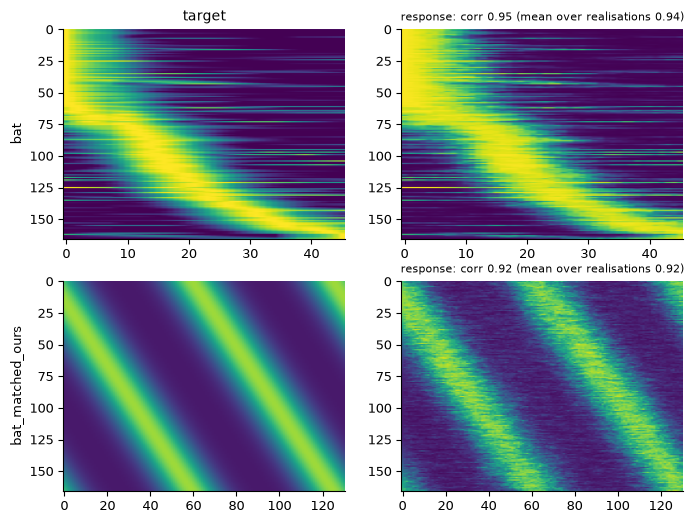

In [3]:
d = fig.load("C_responses")
keys = [k[:-7] for k in d if k.endswith("_target")]
F, axs = plt.subplots(len(keys), 2, figsize=(8, 3 * len(keys)))
axs = np.atleast_2d(axs)
for row, k in enumerate(keys):
    axs[row, 0].imshow(d[f"{k}_target"], aspect="auto", vmin=0, vmax=1); axs[row, 0].set_ylabel(k)
    axs[row, 1].imshow(d[f"{k}_resp"], aspect="auto", vmin=0, vmax=1)
    axs[row, 1].set_title(f"response: corr {float(d[f'{k}_corr1']):.2f} (mean over realisations {float(d[f'{k}_corr_mean']):.2f})", fontsize=8)
axs[0, 0].set_title("target"); fig.savefig("C_responses", F); plt.show()

## Panel D — mean matrices and profiles: experimental vs synthetic matched

In [4]:
def compare(exp, syn):
    We, Ws = runs[exp].summary["mean_W"], runs[syn].summary["mean_W"]
    d, ce = cv.centred_profile(cv.profile_from_matrix(We)); _, cs = cv.centred_profile(cv.profile_from_matrix(Ws))
    nz = d != 0
    return {"We": We, "Ws": Ws, "d": d, "cp_exp": ce, "cp_syn": cs, "corr_W": pearson(We, Ws), "corr_cp": pearson(ce, cs), "corr_cp_no0": pearson(ce[nz], cs[nz])}
for exp in [k for k in ("bat", "mec") if k in runs]:
    for which in ("ours", "paper"):
        fig.save(f"D_{exp}_{which}", **compare(exp, f"{exp}_matched_{which}"))

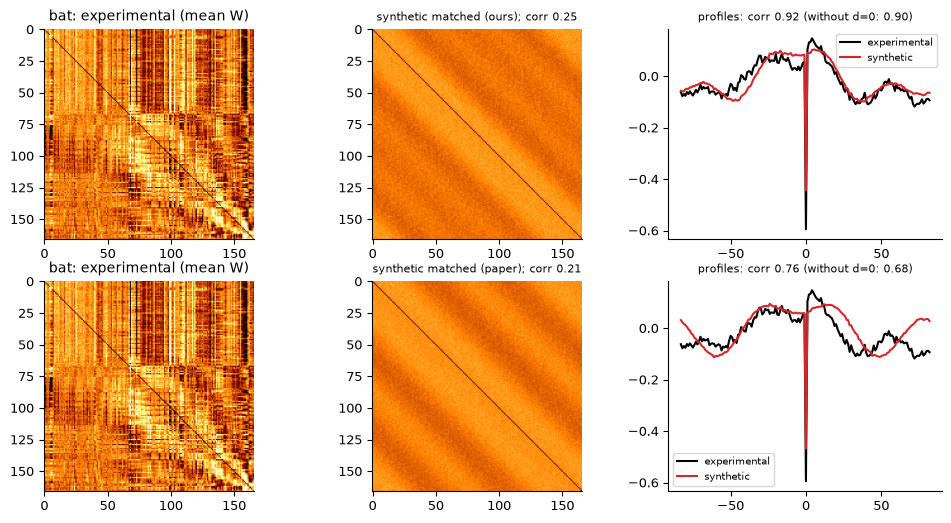

In [5]:
for exp in [k for k in ("bat", "mec") if k in runs]:
    F, axs = plt.subplots(2, 3, figsize=(12, 6))
    for row, which in enumerate(("ours", "paper")):
        d = fig.load(f"D_{exp}_{which}"); c = np.percentile(np.abs(d["We"]), 99)
        axs[row, 0].imshow(d["We"], cmap="afmhot", vmin=-c, vmax=c); axs[row, 0].set_title(f"{exp}: experimental (mean W)")
        axs[row, 1].imshow(d["Ws"], cmap="afmhot", vmin=-c, vmax=c); axs[row, 1].set_title(f"synthetic matched ({which}); corr {float(d['corr_W']):.2f}", fontsize=8)
        axs[row, 2].plot(d["d"], d["cp_exp"], "k", label="experimental"); axs[row, 2].plot(d["d"], d["cp_syn"], "tab:red", label="synthetic")
        axs[row, 2].set_title(f"profiles: corr {float(d['corr_cp']):.2f} (without d=0: {float(d['corr_cp_no0']):.2f})", fontsize=8); axs[row, 2].legend(fontsize=7)
    fig.savefig(f"D_{exp}", F); plt.show()

## Panels E, F — mouse MEC (skeleton)

In [6]:
if not mec_ok:
    print("MEC data not available -- panels E, F skipped [DATA]; the C/D cells above include the mouse rows once mec.path is set")

MEC data not available -- panels E, F skipped [DATA]; the C/D cells above include the mouse rows once mec.path is set


## Supp. 7 — motif abundances: data-trained vs matched synthetic networks

In [7]:
pairs = {exp: (motifs(runs[exp].summary["mean_W"]), motifs(runs[f"{exp}_matched_ours"].summary["mean_W"])) for exp in ("bat", "mec") if exp in runs}
K = ("tau_rec", "tau_div", "tau_chn", "tau_con")
fig.save("S7_motifs", **{f"{exp}_{src}_{k}": (p[0] if src == "data" else p[1])[k] for exp, p in pairs.items() for src in ("data", "syn") for k in K})

WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig3/S7_motifs.npz')

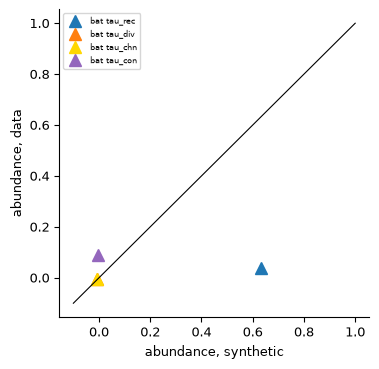

{'bat_data_tau_rec': 0.04, 'bat_data_tau_div': -0.004, 'bat_data_tau_chn': -0.007, 'bat_data_tau_con': 0.09, 'bat_syn_tau_rec': 0.632, 'bat_syn_tau_div': -0.006, 'bat_syn_tau_chn': -0.008, 'bat_syn_tau_con': -0.005}


In [8]:
d = fig.load("S7_motifs")
F, ax = plt.subplots(figsize=(4, 4))
for exp, mk in (("mec", "o"), ("bat", "^")):
    for k, c in zip(K, ("tab:blue", "tab:orange", "gold", "tab:purple")):
        if f"{exp}_data_{k}" in d:
            ax.plot(float(d[f"{exp}_syn_{k}"]), float(d[f"{exp}_data_{k}"]), mk, color=c, ms=9, label=f"{exp} {k}")
lim = [-0.1, 1]; ax.plot(lim, lim, "k", lw=0.8); ax.set_xlabel("abundance, synthetic"); ax.set_ylabel("abundance, data"); ax.legend(fontsize=6)
fig.savefig("S7_motifs", F); plt.show()
print({k: round(float(v), 3) for k, v in d.items() if k != "_params"})

## Acceptance

In [9]:
c = fig.load("C_responses"); dd = fig.load("D_bat_ours"); m = fig.load("S7_motifs")
checks = [
    {"item": "bat: target-response correlation", "criterion": "about 0.90 (|x - 0.9| < 0.07)", "value": float(c["bat_corr_mean"]), "passed": bool(abs(c["bat_corr_mean"] - 0.9) < 0.07)},
    {"item": "bat: synthetic matched control learned", "criterion": "corr > 0.8 (paper 0.90)", "value": float(c["bat_matched_ours_corr_mean"]), "passed": bool(c["bat_matched_ours_corr_mean"] > 0.8)},
    {"item": "bat: mean matrices differ (exp vs synthetic)", "criterion": "corr < 0.3 (paper 0.13)", "value": float(dd["corr_W"]), "passed": bool(dd["corr_W"] < 0.3)},
    {"item": "bat: profiles agree (exp vs synthetic, ours)", "criterion": "corr > 0.6 (paper 0.83)", "value": {"with_d0": float(dd["corr_cp"]), "without_d0": float(dd["corr_cp_no0"])},
     "passed": bool(dd["corr_cp_no0"] > 0.6)},
    {"item": "bat: profile agreement with the paper's fit", "criterion": "reported", "value": float(fig.load("D_bat_paper")["corr_cp_no0"]), "passed": None},
    {"item": "bat motifs: chain and convergent about 0", "criterion": "|tau_chn|, |tau_con| < 0.05", "value": [float(m["bat_data_tau_chn"]), float(m["bat_data_tau_con"])],
     "passed": bool(abs(m["bat_data_tau_chn"]) < 0.05 and abs(m["bat_data_tau_con"]) < 0.05)},
]
if "mec" in runs:
    checks.append({"item": "mouse: target-response corr", "criterion": "about 0.95", "value": float(c["mec_corr_mean"]), "passed": bool(abs(c["mec_corr_mean"] - 0.95) < 0.05)})
else:
    checks.append({"item": "mouse panels (E, F; Supp. 7 circles)", "criterion": "blocked [DATA]", "value": None, "passed": None})
fig.checks(checks)

[PASS] bat: target-response correlation: 0.9369594703466941
[PASS] bat: synthetic matched control learned: 0.9230357076744273
[PASS] bat: mean matrices differ (exp vs synthetic): 0.24583929247301634
[PASS] bat: profiles agree (exp vs synthetic, ours): {'with_d0': 0.9183104894302753, 'without_d0': 0.8997060032034896}
[info] bat: profile agreement with the paper's fit: 0.6810988805987052
[FAIL] bat motifs: chain and convergent about 0: [-0.006596339350294272, 0.09037133199656294]
[info] mouse panels (E, F; Supp. 7 circles): None


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig3/acceptance.json')